# Sombra: o calor perigoso das próximas 24 horas

**GS 2026.2 · IA & Machine Learning** · André Nakamatsu Rocha (RM555004) · João Marcelo Furtado Romero (RM555199) · Matheus Rivera Montovaneli (RM555499)

## 1. O problema e os dados

Em ondas de calor, a pessoa idosa que mora sozinha corre mais risco: sente menos sede e quase nunca percebe que a casa virou um forno. O Sombra quer avisar a família **antes** do pior momento, e não depois. Daí a pergunta deste notebook:

> **Com o que a estação do INMET mediu nas últimas 24 horas, o índice de calor em São Paulo vai chegar ao nível de risco nas próximas 24 horas?**

É uma classificação binária. Não avisar num dia perigoso custa mais do que um aviso a mais, então olhamos primeiro para o **recall**, sem esquecer o custo dos alarmes falsos: na entrevista, a família pediu para não receber alerta à toa.

**Fonte:** INMET, dados históricos horários ([portal.inmet.gov.br/dadoshistoricos](https://portal.inmet.gov.br/dadoshistoricos)), estação automática **A701, São Paulo – Mirante de Santana**, 2010 a 2025. São medições reais e públicas; nada aqui é simulado. Proveniência e SHA-256 de cada arquivo em [`dados/README.md`](../dados/README.md).

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from sombra_ml import figuras as fig
from sombra_ml.dados import FUSO_LOCAL, carregar_brutos, conferir_manifesto, limpar
from sombra_ml.features import CATALOGO, LIMIAR_ALVO_C, NOMES_DAS_FEATURES, montar_amostras, orvalho_c, series_base
from sombra_ml.indice_calor import LIMIARES_C

fig.aplicar_estilo()
pd.options.display.float_format = "{:,.3f}".format
BRUTOS = RAIZ / "dados" / "brutos"

conferir_manifesto(BRUTOS)  # falha se algum CSV não for o que veio do INMET
bruto = carregar_brutos(BRUTOS)
print(f"{len(bruto):,} horas · {bruto.index.min():%d/%m/%Y} a {bruto.index.max():%d/%m/%Y} (UTC) · {bruto.shape[1]} medições")
bruto.describe().T[["count", "mean", "min", "max"]]

140,256 horas · 01/01/2010 a 31/12/2025 (UTC) · 7 medições


,count,mean,min,max
temperatura_c,"139,363.000",20.539,4.100,37.300
umidade_pct,"139,514.000",69.306,12.000,100.000
orvalho_inmet_c,"139,512.000",14.034,-6.900,25.400
pressao_hpa,"139,516.000",927.155,913.100,940.300
radiacao_kj_m2,"74,300.000","1,296.218",0.000,"3,999.600"
vento_ms,"139,513.000",1.846,0.000,10.900
chuva_mm,"139,077.000",0.180,0.000,82.000


## 2. Limpeza

Regras, todas em funções testadas (`sombra_ml/dados.py`, `tests/test_dados.py`):

- `-9999` e campo vazio viram **ausente**: o INMET usa esse código para falha de sensor ou de transmissão.
- O horário vem em **UTC**; dias, horas e estações são calculados em `America/Sao_Paulo`.
- Buracos de **até 3 h** em grandezas contínuas são interpolados. Chuva e radiação não, porque são acumulados da hora.
- **Dias locais com mais de 25% faltando** são descartados.
- Uma hora interpolada **nunca vira amostra**. Assim, nenhuma amostra usa, nem indiretamente, um valor posterior a ela.

In [2]:
limpa, relatorio = limpar(bruto)
pd.DataFrame(
    {"ausentes na origem": relatorio.ausentes_na_origem, "fora da faixa física": relatorio.fora_da_faixa}
).assign(**{"% ausente": lambda t: 100 * t["ausentes na origem"] / relatorio.horas})

,ausentes na origem,fora da faixa física,% ausente
temperatura_c,893,0,0.637
umidade_pct,742,0,0.529
orvalho_inmet_c,744,0,0.530
pressao_hpa,740,0,0.528
radiacao_kj_m2,65956,0,47.025
vento_ms,743,0,0.530
chuva_mm,1179,0,0.841


In [3]:
display(Markdown(
    f"- Horas interpoladas (temperatura): **{relatorio.horas_interpoladas}**\n"
    f"- Dias locais descartados: **{relatorio.dias_descartados}** ({relatorio.horas_descartadas} horas)\n"
    f"- Horas realmente medidas e aproveitadas: **{limpa['observada'].mean():.1%}**\n\n"
    "A radiação tem muitos ausentes porque o INMET não a informa à noite; por isso ela entra só como soma na janela."
))

- Horas interpoladas (temperatura): **160**
- Dias locais descartados: **40** (960 horas)
- Horas realmente medidas e aproveitadas: **99.2%**

A radiação tem muitos ausentes porque o INMET não a informa à noite; por isso ela entra só como soma na janela.

## 3. O alvo: qual limiar é possível nos dados reais?

O índice de calor segue a equação da NWS, com os mesmos 20 vetores de teste usados em C#, Java, C++ e TypeScript. O alvo é `1` quando o **máximo das próximas 24 horas** alcança o limiar. A tabela da NWS oferece duas âncoras: `CAUTELA_EXTREMA` (32,22 °C) e `PERIGO` (39,44 °C). A escolha olha **só o período de treino**.

In [4]:
base = series_base(limpa)
amostras = montar_amostras(limpa)
ano_local = amostras.index.tz_convert(FUSO_LOCAL).year
pico_treino = amostras.loc[ano_local <= 2021, "pico_futuro_c"]
linhas = [("ATENCAO", LIMIARES_C["ATENCAO"]), ("CAUTELA_EXTREMA", LIMIARES_C["CAUTELA_EXTREMA"]), ("PERIGO", LIMIARES_C["PERIGO"])]
pd.DataFrame(
    [{"nível (NWS)": n, "limiar (°C)": v, "amostras positivas": int((pico_treino >= v).sum()), "% positivas": 100 * (pico_treino >= v).mean()} for n, v in linhas]
)

,nível (NWS),limiar (°C),amostras positivas,% positivas
0,ATENCAO,26.670,7456,42.927
1,CAUTELA_EXTREMA,32.220,430,2.476
2,PERIGO,39.440,0,0.000


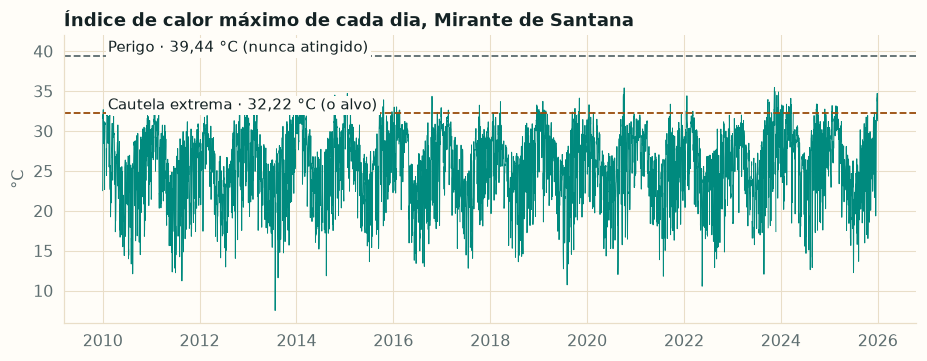

In [5]:
diario = base["indice_calor_c"].tz_convert(FUSO_LOCAL).resample("D").max()
figura, eixo = plt.subplots(figsize=(10, 3.4))
eixo.plot(diario.index, diario, color=fig.PERSISTENCIA, linewidth=0.6)
for nome, cor, texto in [("CAUTELA_EXTREMA", fig.LIMIAR, "Cautela extrema · 32,22 °C (o alvo)"), ("PERIGO", fig.TINTA_SUAVE, "Perigo · 39,44 °C (nunca atingido)")]:
    eixo.axhline(LIMIARES_C[nome], color=cor, linewidth=1.2, linestyle="--")
    eixo.text(diario.index[40], LIMIARES_C[nome] + 0.5, texto, color=fig.TINTA, fontsize=9.5, bbox={"facecolor": fig.FUNDO, "edgecolor": "none", "pad": 1.5})
eixo.set_title("Índice de calor máximo de cada dia, Mirante de Santana")
eixo.set_ylabel("°C")
eixo.set_ylim(top=42)
fig.salvar(figura, "01_indice_diario")
plt.show()

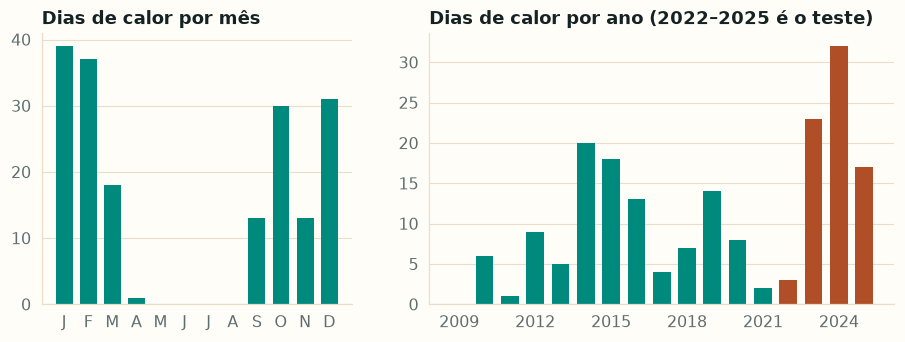

**Decisão: limiar de 32.22 °C (`CAUTELA_EXTREMA`).** Em 16 anos, o maior índice de calor medido na A701 foi **35.47 °C**: o nível `PERIGO` da tabela **nunca** ocorreu, e um alvo sem nenhum exemplo positivo não pode ser treinado. `ATENCAO` seria comum demais para ser um aviso. Com `CAUTELA_EXTREMA`, **2.5%** das amostras de treino são positivas: classes desbalanceadas, mas com exemplos reais. Para a pessoa idosa isso faz sentido: os limites pessoais do Sombra (R3) ficam abaixo da tabela geral, e o calor que a NWS chama de cautela extrema já é perigoso para quem tem 85 anos e cardiopatia.

In [6]:
perigosos = diario >= LIMIAR_ALVO_C
por_mes = perigosos.groupby(perigosos.index.month).sum()
por_ano = perigosos.groupby(perigosos.index.year).sum()
figura, (esq, dir_) = plt.subplots(1, 2, figsize=(10, 3.2), width_ratios=[1, 1.5])
esq.bar(por_mes.index, por_mes, color=fig.PERSISTENCIA, width=0.7)
esq.set_xticks(range(1, 13), list("JFMAMJJASOND"))
esq.set_title("Dias de calor por mês")
esq.grid(axis="x", visible=False)
dir_.bar(por_ano.index, por_ano, color=[fig.XGBOOST if a >= 2022 else fig.PERSISTENCIA for a in por_ano.index], width=0.7)
dir_.set_xticks(por_ano.index[::3])
dir_.set_title("Dias de calor por ano (2022–2025 é o teste)")
dir_.grid(axis="x", visible=False)
fig.salvar(figura, "02_dias_de_calor")
plt.show()
display(Markdown(
    f"**Decisão: limiar de {LIMIAR_ALVO_C:.2f} °C (`CAUTELA_EXTREMA`).** Em 16 anos, o maior índice de calor medido na A701 foi "
    f"**{base['indice_calor_c'].max():.2f} °C**: o nível `PERIGO` da tabela **nunca** ocorreu, e um alvo sem nenhum exemplo positivo não pode ser treinado. "
    f"`ATENCAO` seria comum demais para ser um aviso. Com `CAUTELA_EXTREMA`, **{(pico_treino >= LIMIAR_ALVO_C).mean():.1%}** das amostras de treino são positivas: "
    "classes desbalanceadas, mas com exemplos reais. Para a pessoa idosa isso faz sentido: os limites pessoais do Sombra (R3) ficam abaixo da tabela geral, "
    "e o calor que a NWS chama de cautela extrema já é perigoso para quem tem 85 anos e cardiopatia."
))

## 4. Features, sem olhar o futuro

Cada amostra enxerga **só a hora atual e as anteriores**, e só o que o Clima Service terá em produção: temperatura, umidade, pressão, radiação, vento e chuva das últimas 24 h. O ponto de orvalho é **calculado** (Magnus), porque o Clima Service não recebe essa medida em produção; a coluna medida pelo INMET serve apenas para conferir a fórmula.

Há uma amostra **a cada 6 h** (0h, 6h, 12h e 18h locais), o que reduz a autocorrelação entre linhas vizinhas.

In [7]:
grupos = pd.Series([f.agregacao if f.variavel != "tempo" else "ciclo (hora e dia do ano)" for f in CATALOGO]).value_counts()
erro_orvalho = (orvalho_c(limpa["temperatura_c"], limpa["umidade_pct"]) - limpa["orvalho_inmet_c"]).abs().mean()
display(Markdown(
    f"**{len(NOMES_DAS_FEATURES)} features** em {len(amostras):,} amostras. O orvalho calculado erra, em média, **{erro_orvalho:.2f} °C** em relação ao medido."
))
grupos.rename("features").to_frame()

**63 features** em 23,071 amostras. O orvalho calculado erra, em média, **0.07 °C** em relação ao medido.

,features
media,19
delta,16
maximo,8
soma,8
atual,6
ciclo (hora e dia do ano),4
minimo,1
amplitude,1


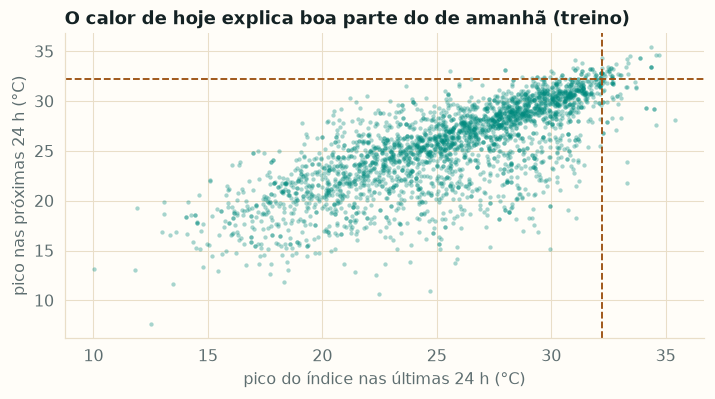

Correlação entre o pico passado e o futuro no treino: **0.75**. Por isso a persistência é um adversário forte, e vira o primeiro baseline.

In [8]:
figura, eixo = plt.subplots(figsize=(7.5, 3.6))
treino = amostras[ano_local <= 2021]
amostra = treino.sample(3000, random_state=42)
eixo.scatter(amostra["indice_calor_maximo_24h"], amostra["pico_futuro_c"], s=8, color=fig.PERSISTENCIA, alpha=0.35, linewidths=0)
eixo.axhline(LIMIAR_ALVO_C, color=fig.LIMIAR, linewidth=1.2, linestyle="--")
eixo.axvline(LIMIAR_ALVO_C, color=fig.LIMIAR, linewidth=1.2, linestyle="--")
eixo.set_xlabel("pico do índice nas últimas 24 h (°C)")
eixo.set_ylabel("pico nas próximas 24 h (°C)")
eixo.set_title("O calor de hoje explica boa parte do de amanhã (treino)")
fig.salvar(figura, "03_persistencia")
plt.show()
correlacao = treino["indice_calor_maximo_24h"].corr(treino["pico_futuro_c"])
display(Markdown(f"Correlação entre o pico passado e o futuro no treino: **{correlacao:.2f}**. Por isso a persistência é um adversário forte, e vira o primeiro baseline."))